# P6: Operasi Morfologi dan Komponen Terhubung (Bagian 3)
SIMUTEH | NIM 2330511014 | Farhan Fadila | SEED 1014

In [1]:
import sys, json
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
PARAM = json.load(open("../hasil/param_praproses.json"))   # hasil Evaluasi P1-P4
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

## Langkah 3.1 Lembar hitung manual (hasil verifikasi kode di sel berikutnya)

In [2]:
B = np.array([[0,0,0,0,0,0,0,0,0],
              [0,1,1,1,0,0,0,0,0],
              [0,1,0,1,0,0,0,1,0],
              [0,1,1,1,0,0,0,0,0],
              [0,0,0,0,1,0,0,0,0],
              [0,0,0,0,0,0,0,0,0],
              [0,0,0,0,0,0,0,0,0],
              [0,1,1,1,1,1,1,0,0],
              [0,0,0,0,0,0,0,0,0]], np.uint8)
se3 = np.ones((3, 3), np.uint8)
def tulis(nm, m): print(nm); print("\n".join(" ".join(str(int(v)) for v in r) for r in m)); print()
for k in (4, 8):
    print("konektivitas", k, "->", cv2.connectedComponents(B, connectivity=k)[0] - 1, "komponen")
er = cv2.erode(B, se3, borderType=cv2.BORDER_CONSTANT, borderValue=0)
op = cv2.morphologyEx(B, cv2.MORPH_OPEN, se3, borderType=cv2.BORDER_CONSTANT, borderValue=0)
cl = cv2.morphologyEx(B, cv2.MORPH_CLOSE, se3, borderType=cv2.BORDER_CONSTANT, borderValue=0)
co = cv2.morphologyEx(cl, cv2.MORPH_OPEN, se3, borderType=cv2.BORDER_CONSTANT, borderValue=0)
tulis("(b) erosi", er); tulis("(b) opening", op); tulis("(c) closing", cl); tulis("(d) closing lalu opening", co)
print("komponen hasil (d) konektivitas 8:", cv2.connectedComponents(co, connectivity=8)[0] - 1)
print("piksel yang ditambah closing:", np.argwhere((cl == 1) & (B == 0)).tolist())

konektivitas 4 -> 4 komponen
konektivitas 8 -> 3 komponen
(b) erosi
0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0

(b) opening
0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0

(c) closing
0 0 0 0 0 0 0 0 0
0 1 1 1 0 0 0 0 0
0 1 1 1 0 0 0 1 0
0 1 1 1 0 0 0 0 0
0 0 0 0 1 0 0 0 0
0 0 0 0 1 0 0 0 0
0 0 0 0 1 0 0 0 0
0 1 1 1 1 1 1 0 0
0 0 0 0 0 0 0 0 0

(d) closing lalu opening
0 0 0 0 0 0 0 0 0
0 1 1 1 0 0 0 0 0
0 1 1 1 0 0 0 0 0
0 1 1 1 0 0 0 0 0
0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0

komponen hasil (d) konektivitas 8: 1
piksel yang ditambah closing: [[2, 2], [5, 4], [6, 4]]


## Langkah 3.2 Citra biner awal (Kode 3.1)

         citra  IoU daun awal  komponen bercak awal  komponen acuan IoU bercak awal
0  teh_041.png          0.996                   224              10           0.822
1  teh_021.png          0.998                   142               2           0.082
2  teh_011.png          0.998                   158               0               -


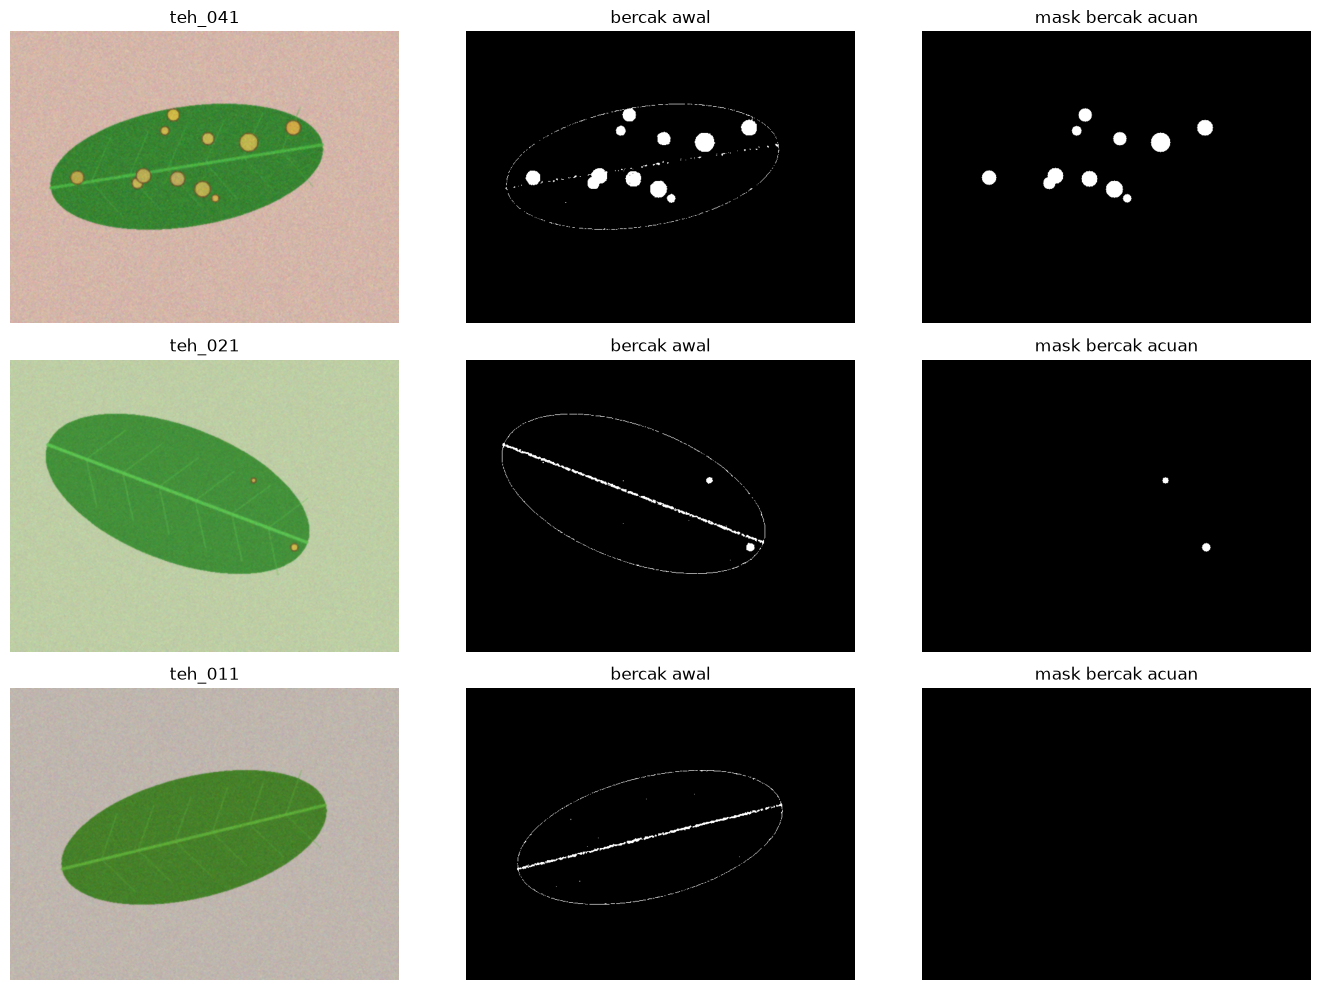

In [3]:
def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents((m > 0).astype(np.uint8), connectivity=konek)[0] - 1

baris, panel, judul = [], [], []
for nama in ["teh_041.png", "teh_021.png", "teh_011.png"]:     # berat, ringan, sehat
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    b0 = bercak_awal(pra_, m_daun, kanal=2, k=4.0)
    baris.append([nama, round(iou(m_daun, md), 3), jumlah_komponen(b0), jumlah_komponen(mb),
                  round(iou(b0, mb), 3) if mb.any() else "-"])
    panel += [pra_, b0, mb]; judul += [nama[:7], "bercak awal", "mask bercak acuan"]
print(pd.DataFrame(baris, columns=["citra", "IoU daun awal", "komponen bercak awal",
                                   "komponen acuan", "IoU bercak awal"]))
tampil(panel, judul, baris=3, ukuran=(14, 10))
plt.savefig("../hasil/p6_citra_biner_awal.png", dpi=120, bbox_inches="tight"); plt.show()

## Langkah 3.3 Enam operasi (Kode 3.2)

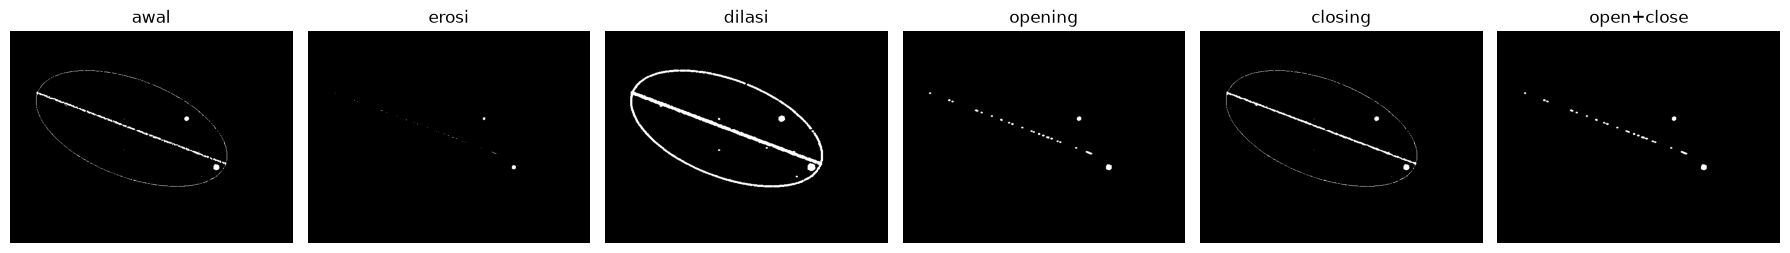

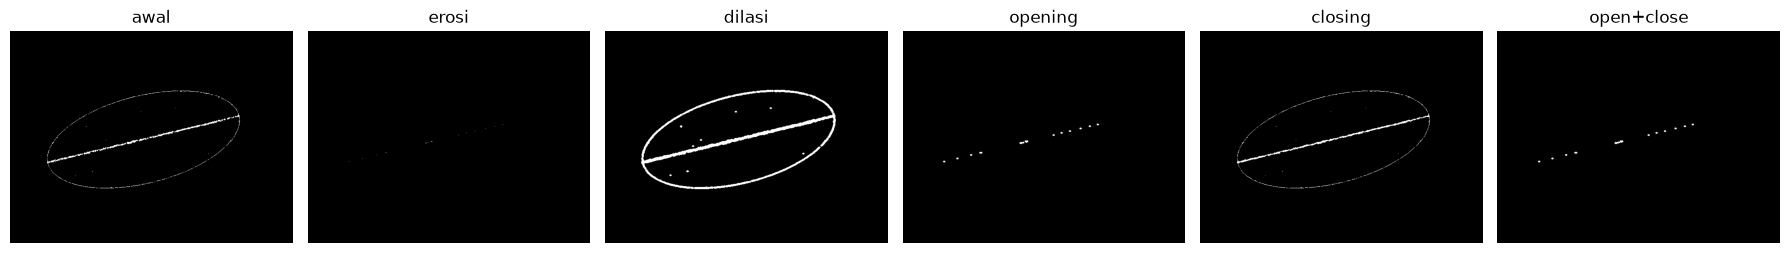

          citra     operasi  komponen  piksel    IoU
0   teh_021.png        awal       142    2692  0.082
1   teh_021.png       erosi        25     144   0.38
2   teh_021.png      dilasi         8    9194  0.025
3   teh_021.png     opening        21     682  0.314
4   teh_021.png     closing       122    2899  0.076
5   teh_021.png  open+close        17     705  0.304
6   teh_011.png        awal       158    2201      -
7   teh_011.png       erosi        14      19      -
8   teh_011.png      dilasi         9    8360      -
9   teh_011.png     opening        12     254      -
10  teh_011.png     closing       129    2364      -
11  teh_011.png  open+close        11     260      -


In [4]:
SE = lambda k, bentuk=cv2.MORPH_ELLIPSE: cv2.getStructuringElement(bentuk, (k, k))

def operasi(b, se):
    return {"awal": b,
            "erosi": cv2.erode(b, se),
            "dilasi": cv2.dilate(b, se),
            "opening": cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
            "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
            "open+close": cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)}

baris = []
for nama in ["teh_021.png", "teh_011.png"]:
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    b0 = bercak_awal(pra_, mask_daun_awal(pra_))
    hasil = operasi(b0, SE(5))
    for nm, m in hasil.items():
        baris.append([nama, nm, jumlah_komponen(m), int((m > 0).sum()),
                      round(iou(m, mb), 3) if mb.any() else "-"])
    tampil(list(hasil.values()), list(hasil.keys()), ukuran=(18, 3))
    plt.savefig(f"../hasil/p6_operasi_{nama[:7]}.png", dpi=120, bbox_inches="tight"); plt.show()
print(pd.DataFrame(baris, columns=["citra", "operasi", "komponen", "piksel", "IoU"]))

## Langkah 3.4 Eksperimen k, bentuk, dan ukuran SE (Kode 3.3, Tabel 9)

In [5]:
bentuk = {"persegi": cv2.MORPH_RECT, "elips": cv2.MORPH_ELLIPSE, "silang": cv2.MORPH_CROSS}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    n_acuan = jumlah_komponen(mb)
    for k in [3, 4, 6]:
        b0 = bercak_awal(pra_, m_daun, k=k)
        for nb, kb in bentuk.items():
            for uk in [3, 5, 7]:
                se = SE(uk, kb)
                m = cv2.morphologyEx(cv2.morphologyEx(b0, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)
                baris.append([d.kelas, k, nb, uk, abs(jumlah_komponen(m) - n_acuan),
                              iou(m, mb) if mb.any() else np.nan])
eks = pd.DataFrame(baris, columns=["kelas", "k", "bentuk", "ukuran", "galat_jumlah", "IoU"])
print(eks.pivot_table(index=["k", "bentuk", "ukuran"], columns="kelas",
                      values=["galat_jumlah", "IoU"]).round(2))
eks.to_csv("../hasil/p6_eksperimen_se.csv", index=False)

                   IoU        galat_jumlah              
kelas            berat ringan        berat ringan  sehat
k bentuk  ukuran                                        
3 elips   3       0.76   0.43        33.60  12.95  20.85
          5       0.79   0.58         1.80   3.55   5.60
          7       0.81   0.70         0.90   0.65   0.90
  persegi 3       0.77   0.47         9.90   6.95   6.55
          5       0.80   0.64         1.85   2.40   4.25
          7       0.79   0.68         1.10   0.30   0.00
  silang  3       0.76   0.43        33.60  12.95  20.85
          5       0.79   0.55         3.95   5.90   8.40
          7       0.81   0.67         1.10   1.95   2.95
4 elips   3       0.79   0.55         6.75   7.95  24.50
          5       0.79   0.64         1.85   2.50   4.10
          7       0.79   0.70         0.90   0.30   0.00
  persegi 3       0.79   0.59         2.80   4.70  10.80
          5       0.79   0.71         0.75   0.45   0.90
          7       0.77   0.65  

In [6]:
# Tabel 9 (k = 4)
t = eks[eks.k == 4].pivot_table(index=["bentuk", "ukuran"], columns="kelas", values=["IoU", "galat_jumlah"]).round(3)
tabel9 = pd.DataFrame({"IoU berat": t[("IoU", "berat")], "IoU ringan": t[("IoU", "ringan")],
                       "Galat berat": t[("galat_jumlah", "berat")], "Galat ringan": t[("galat_jumlah", "ringan")],
                       "Galat sehat": t[("galat_jumlah", "sehat")]})
tabel9 = tabel9.reindex([(b, u) for b in ["persegi", "elips", "silang"] for u in [3, 5, 7]])
print(tabel9)
tabel9.to_csv("../hasil/p6_tabel9.csv")
# tanpa morfologi sebagai pembanding (k = 4)
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file); pra_ = praproses(img, PARAM)
    b0 = bercak_awal(pra_, mask_daun_awal(pra_), k=4)
    baris.append([d.kelas, abs(jumlah_komponen(b0) - jumlah_komponen(mb)), iou(b0, mb) if mb.any() else np.nan])
print(pd.DataFrame(baris, columns=["kelas", "galat_jumlah", "IoU"]).groupby("kelas").mean().round(3))

                IoU berat  IoU ringan  Galat berat  Galat ringan  Galat sehat
bentuk  ukuran                                                               
persegi 3           0.789       0.590         2.80          4.70        10.80
        5           0.794       0.707         0.75          0.45         0.90
        7           0.767       0.646         1.20          0.40         0.00
elips   3           0.786       0.555         6.75          7.95        24.50
        5           0.794       0.644         1.85          2.50         4.10
        7           0.793       0.700         0.90          0.30         0.00
silang  3           0.786       0.555         6.75          7.95        24.50
        5           0.797       0.631         2.60          5.05         7.40
        7           0.794       0.674         0.80          0.45         0.05
        galat_jumlah    IoU
kelas                      
berat         299.70  0.674
ringan        262.85  0.253
sehat         468.50    NaN


## Langkah 3.5 Gradien morfologi sebagai tepi daun (Kode 3.4)

In [7]:
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    grad = cv2.morphologyEx(m_daun, cv2.MORPH_GRADIENT, SE(3))     # dilasi - erosi
    canny = tepi_canny(cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY))
    ad = tepi_acuan(md)
    baris.append([d.kondisi_cahaya, skor_tepi(grad, ad)[2], skor_tepi(canny, ad)[2]])
gm = pd.DataFrame(baris, columns=["kondisi", "F1 gradien morfologi", "F1 Canny"])
print(gm.groupby("kondisi").mean().round(3))
print(gm[["F1 gradien morfologi", "F1 Canny"]].mean().round(3))

                F1 gradien morfologi  F1 Canny
kondisi                                       
bayangan                       0.934     0.933
gelap                          0.990     0.915
kontras_rendah                 0.457     0.000
normal                         0.990     0.896
terang                         0.960     0.916
F1 gradien morfologi    0.866
F1 Canny                0.732
dtype: float64


## Langkah 3.6 Panel bentuk SE (kerjakan sendiri)

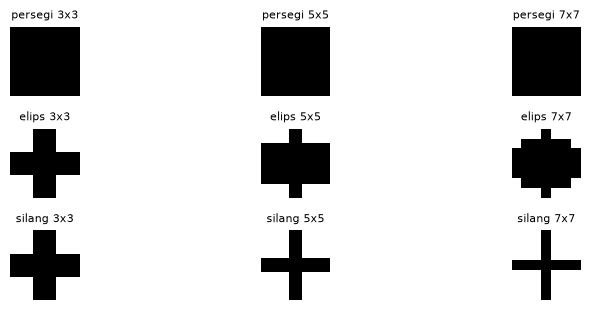

persegi 3 
 [[1 1 1]
 [1 1 1]
 [1 1 1]]
persegi 5 
 [[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]
persegi 7 
 [[1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]]
elips 3 
 [[0 1 0]
 [1 1 1]
 [0 1 0]]
elips 5 
 [[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]
elips 7 
 [[0 0 0 1 0 0 0]
 [0 1 1 1 1 1 0]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [0 1 1 1 1 1 0]
 [0 0 0 1 0 0 0]]
silang 3 
 [[0 1 0]
 [1 1 1]
 [0 1 0]]
silang 5 
 [[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]
silang 7 
 [[0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [1 1 1 1 1 1 1]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]]


In [8]:
plt.figure(figsize=(9, 3.2))
for i, (nb, kb) in enumerate(bentuk.items()):
    for j, uk in enumerate([3, 5, 7]):
        plt.subplot(3, 3, 3 * i + j + 1)
        plt.imshow(cv2.getStructuringElement(kb, (uk, uk)), cmap="gray_r", vmin=0, vmax=1)
        plt.title(f"{nb} {uk}x{uk}", fontsize=8); plt.axis("off")
plt.tight_layout(); plt.savefig("../hasil/p6_panel_se.png", dpi=130); plt.show()
for nb, kb in bentuk.items():
    for uk in (3, 5, 7):
        print(nb, uk, "\n", cv2.getStructuringElement(kb, (uk, uk)))

### Bukti tambahan untuk P3.2 sampai P3.5

In [9]:
# P3.2: konektivitas 4 vs 8 pada mask acuan dan pada hasil pembersihan (elips 5, k = 4), 60 citra
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file); pra_ = praproses(img, PARAM)
    m = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, mask_daun_awal(pra_), k=4), cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))
    baris.append([d.kelas, jumlah_komponen(mb, 4), jumlah_komponen(mb, 8), jumlah_komponen(m, 4), jumlah_komponen(m, 8)])
kon = pd.DataFrame(baris, columns=["kelas", "acuan_4", "acuan_8", "hasil_4", "hasil_8"])
print(kon.groupby("kelas").mean().round(2))
print("citra dengan selisih 4 vs 8 pada acuan:", int((kon.acuan_4 != kon.acuan_8).sum()), "| pada hasil:", int((kon.hasil_4 != kon.hasil_8).sum()), "dari 60")

        acuan_4  acuan_8  hasil_4  hasil_8
kelas                                     
berat      8.95     8.95     9.45      9.4
ringan     2.00     2.00     4.30      4.3
sehat      0.00     0.00     4.20      4.1
citra dengan selisih 4 vs 8 pada acuan: 0 | pada hasil: 2 dari 60


In [10]:
# P3.3: apa yang tersisa pada daun sehat setelah open+close (elips 5, k = 4)
baris = []
for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, mb = muat(d.nama_file); pra_ = praproses(img, PARAM)
    m = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, mask_daun_awal(pra_), k=4), cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))
    n, l, st, c = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8), connectivity=8)
    luas = st[1:, cv2.CC_STAT_AREA]; lebar = st[1:, cv2.CC_STAT_WIDTH]
    baris.append([d.nama_file, d.kondisi_cahaya, n - 1, int(luas.max()) if n > 1 else 0, int(lebar.max()) if n > 1 else 0,
                  int((luas == 17).sum())])
sis = pd.DataFrame(baris, columns=["citra", "kondisi", "komponen", "luas_terbesar", "lebar_terbesar", "komponen_17px"])
print(sis[sis.komponen > 0].to_string(index=False))
print("citra sehat dengan sisa:", int((sis.komponen > 0).sum()), "dari 20; ukuran SE elips 5 x 5 = ", int(SE(5).sum()), "piksel")

      citra kondisi  komponen  luas_terbesar  lebar_terbesar  komponen_17px
teh_001.png  normal        13            149              36              4
teh_002.png   gelap        14             67              16              9
teh_003.png  terang         3           1120             273              0
teh_006.png  normal         1             17               5              1
teh_008.png  terang         1             17               5              1
teh_011.png  normal        11             82              20              9
teh_012.png   gelap        13             58              14              4
teh_013.png  terang         5             33               8              3
teh_016.png  normal        18            139              36              5
teh_017.png   gelap         3             22               6              2
citra sehat dengan sisa: 10 dari 20; ukuran SE elips 5 x 5 =  17 piksel


In [11]:
# P3.4: ketepatan piksel bercak setelah pembersihan (elips 5, k = 4)
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file); pra_ = praproses(img, PARAM)
    m = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, mask_daun_awal(pra_), k=4), cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5)) > 0
    a = mb > 0
    baris.append([d.kelas, (m & a).sum() / max(m.sum(), 1), (m & a).sum() / a.sum(), m.sum() / a.sum()])
print(pd.DataFrame(baris, columns=["kelas", "presisi_piksel", "recall_piksel", "rasio_luas_hasil/acuan"]).groupby("kelas").mean().round(3))
print("elips 3x3 == silang 3x3 :", bool((cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3)) == cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))).all()))

        presisi_piksel  recall_piksel  rasio_luas_hasil/acuan
kelas                                                        
berat            0.890          0.846                   0.911
ringan           0.839          0.787                   1.632
elips 3x3 == silang 3x3 : True


In [12]:
# P3.5: gradien morfologi vs Canny (Gray seperti pada Kode 3.4, dan R) per kondisi, serta IoU mask daun awal
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file); pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_); ad = tepi_acuan(md)
    grad = cv2.morphologyEx(m_daun, cv2.MORPH_GRADIENT, SE(3))
    baris.append([d.kondisi_cahaya, iou(m_daun, md), skor_tepi(grad, ad)[2],
                  skor_tepi(tepi_canny(cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ad)[2], skor_tepi(tepi_canny(pra_[:, :, 2]), ad)[2]])
bd = pd.DataFrame(baris, columns=["kondisi", "IoU mask daun awal", "F1 grad. morfologi", "F1 Canny Gray", "F1 Canny R"])
print(bd.groupby("kondisi").mean().round(3))
print("IoU mask daun awal terendah pada kontras rendah:", bd[bd.kondisi == "kontras_rendah"]["IoU mask daun awal"].min().round(3))

                IoU mask daun awal  F1 grad. morfologi  F1 Canny Gray  F1 Canny R
kondisi                                                                          
bayangan                     0.996               0.934          0.933       0.922
gelap                        0.998               0.990          0.915       0.918
kontras_rendah               0.918               0.457          0.000       0.928
normal                       0.997               0.990          0.896       0.909
terang                       0.994               0.960          0.916       0.904
IoU mask daun awal terendah pada kontras rendah: 0.612


In [13]:
# P3.4: berapa bercak ASLI (mask acuan) yang hilang bila hanya dikenai opening dengan SE tertentu
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    n0, l0, st0, _ = cv2.connectedComponentsWithStats((mb > 0).astype(np.uint8), connectivity=8)
    for nb, kb in bentuk.items():
        for uk in [3, 5, 7]:
            op_ = cv2.morphologyEx(mb, cv2.MORPH_OPEN, SE(uk, kb))
            hilang = sum(1 for i in range(1, n0) if not (op_[l0 == i] > 0).any())
            baris.append([d.kelas, nb, uk, n0 - 1, hilang])
asli = pd.DataFrame(baris, columns=["kelas", "bentuk", "ukuran", "bercak_asli", "bercak_hilang"])
h = asli.groupby(["kelas", "bentuk", "ukuran"])[["bercak_asli", "bercak_hilang"]].sum()
h["persen_hilang"] = (100 * h.bercak_hilang / h.bercak_asli).round(1)
print(h.loc[["ringan", "berat"]].loc[(slice(None), ["persegi", "elips"], [3, 5, 7]), :])
luas = [st0[i, cv2.CC_STAT_AREA] for _, d in label[label.kelas != "sehat"].iterrows()
        for st0 in [cv2.connectedComponentsWithStats((muat(d.nama_file)[2] > 0).astype(np.uint8), connectivity=8)[2]] for i in range(1, len(st0))]
print("luas bercak asli (px): min", int(min(luas)), "median", int(np.median(luas)), "maks", int(max(luas)), "| jumlah", len(luas))

                       bercak_asli  bercak_hilang  persen_hilang
kelas  bentuk  ukuran                                           
ringan persegi 3                40              0            0.0
berat  persegi 3               179              0            0.0
ringan persegi 5                40              0            0.0
berat  persegi 5               179              0            0.0
ringan persegi 7                40              0            0.0
berat  persegi 7               179              0            0.0
ringan elips   3                40              0            0.0
berat  elips   3               179              0            0.0
ringan elips   5                40              0            0.0
berat  elips   5               179              0            0.0
ringan elips   7                40              0            0.0
berat  elips   7               179              0            0.0
luas bercak asli (px): min 81 median 377 maks 1110 | jumlah 219


# Bagian 4. Komponen terhubung dan pengukuran bercak

## Langkah 4.1 Lembar hitung manual
Dasar: hasil 3.1 butir d) = blok padat 3 x 3 (baris 1 sampai 3, kolom 1 sampai 3) dan garis 1 x 6 pada baris ke-8 citra B. 1 piksel = 0,4375 mm, jadi 1 piksel persegi = 0,4375^2 = 0,19141 mm^2. Keliling = jumlah sisi piksel yang berbatasan dengan latar.

**a) Bercak 3 x 3**
- Luas = 9 piksel = 9 x 0,19141 = **1,723 mm^2**
- Keliling = 4 x 3 = **12** sisi
- Kebulatan = 4 pi x 9 / 12^2 = 36 pi / 144 = pi / 4 = **0,785**
- Rasio aspek = 3 / 3 = **1,0**

**b) Garis 1 x 6**
- Luas = 6 piksel = 6 x 0,19141 = **1,148 mm^2**
- Keliling = 2 x (6 + 1) = **14** sisi
- Kebulatan = 4 pi x 6 / 14^2 = 24 pi / 196 = **0,385**
- Rasio aspek = 6 / 1 = **6,0**

**c) Aturan sederhana**: dengan bulat_min = 0,5 dan rasio_maks = 1,8, bercak 3 x 3 (0,785 dan 1,0) lolos, sedangkan garis (0,385 dan 6,0) ditolak oleh kedua syarat.

In [14]:
# verifikasi lembar hitung 4.1, dan perbandingan dengan ukuran OpenCV (arcLength pada kontur)
MM = 0.4375
def ukur_manual(m):
    m = np.pad(m.astype(int), 1)
    luas = int(m.sum())
    sisi = int(sum(((m[1:-1, 1:-1] == 1) & (np.roll(m, s, ax)[1:-1, 1:-1] == 0)).sum() for ax in (0, 1) for s in (1, -1)))
    return luas, sisi, round(luas * MM**2, 3), round(4*np.pi*luas/sisi**2, 3)
blok = np.ones((3, 3), np.uint8); garis = np.ones((1, 6), np.uint8)
for nm, m in [("blok 3x3", blok), ("garis 1x6", garis)]:
    luas, sisi, mm2, bul = ukur_manual(m)
    kont, _ = cv2.findContours(np.pad(m, 2), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    arc = cv2.arcLength(kont[0], True); w, h = cv2.minAreaRect(kont[0])[1]
    print(f"{nm}: luas {luas} px = {mm2} mm2 | keliling sisi {sisi}, kebulatan {bul} | OpenCV: arcLength {arc:.1f}, "
          f"kebulatan {4*np.pi*luas/arc**2:.3f}, minAreaRect {w:.0f} x {h:.0f}")

blok 3x3: luas 9 px = 1.723 mm2 | keliling sisi 12, kebulatan 0.785 | OpenCV: arcLength 8.0, kebulatan 1.767, minAreaRect 2 x 2
garis 1x6: luas 6 px = 1.148 mm2 | keliling sisi 14, kebulatan 0.385 | OpenCV: arcLength 10.0, kebulatan 0.754, minAreaRect 5 x 0


## Langkah 4.2 Label dan ukur (Kode 4.1, Tabel 10)

konektivitas 4: 10 komponen
konektivitas 8: 10 komponen
   label  luas_px  luas_mm2  keliling_px  kebulatan  rasio_aspek   cx   cy
0      1      378     72.35         70.5       0.95         1.05  268  136
1      2      533    102.02         84.8       0.93         1.00  465  158
2      3      200     38.28         50.6       0.98         1.14  253  162
3      4      378     72.35         71.5       0.93         1.05  324  175
4      5      805    154.08        103.5       0.94         1.07  392  181
5      6      762    145.85        109.8       0.79         1.48  215  241
6      7      450     86.13         78.2       0.93         1.00  109  240
7      8      507     97.04         85.4       0.87         1.00  274  242
8      9      610    116.76         90.4       0.94         1.08  316  258
9     10      147     28.14         43.2       0.99         1.17  337  274
total luas: 4770 px = 913.0 mm2


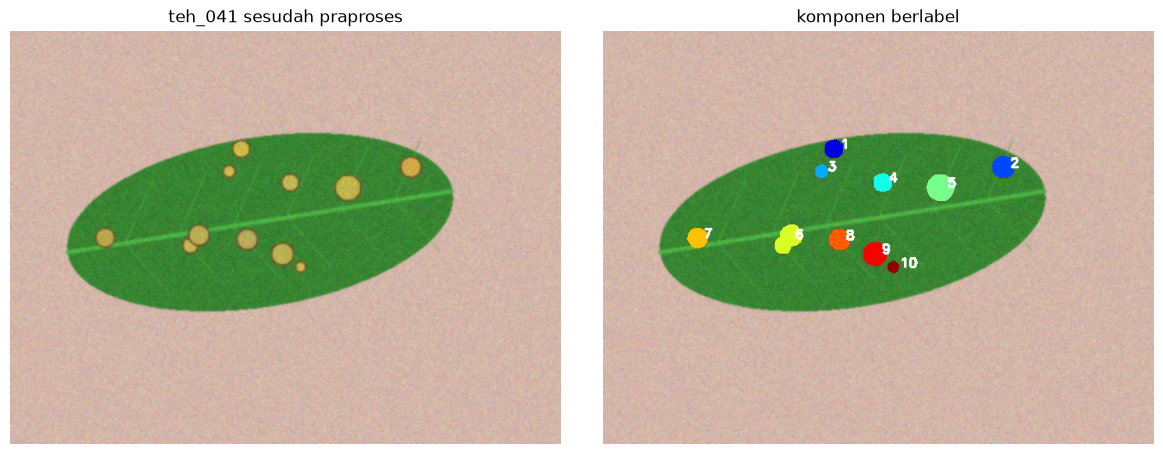

In [15]:
MM_PER_PX = 0.4375            # dari lembar hitung P2: Z = 200 mm, lebar kerja 640 px

def ukur_komponen(m, konek=8):
    n, lbl, st, cen = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8), connectivity=konek)
    baris = []
    for i in range(1, n):
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL,
                                     cv2.CHAIN_APPROX_NONE)
        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * A / keliling ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)
        baris.append([i, A, round(A * MM_PER_PX ** 2, 2), round(keliling, 1), round(kebulatan, 2),
                      round(rasio, 2), int(cen[i][0]), int(cen[i][1])])
    kolom = ["label", "luas_px", "luas_mm2", "keliling_px", "kebulatan", "rasio_aspek", "cx", "cy"]
    return pd.DataFrame(baris, columns=kolom), lbl

img, md, mb = muat("teh_041.png")
pra_ = praproses(img, PARAM)
m_daun = mask_daun_awal(pra_)
bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))
for konek in [4, 8]:
    print(f"konektivitas {konek}: {jumlah_komponen(bersih, konek)} komponen")
tabel_kom, lbl = ukur_komponen(bersih)
print(tabel_kom)
print("total luas:", int(tabel_kom.luas_px.sum()), "px =", round(tabel_kom.luas_mm2.sum(), 2), "mm2")

warna = cv2.applyColorMap((lbl * (255 // max(lbl.max(), 1))).astype(np.uint8), cv2.COLORMAP_JET)
warna[lbl == 0] = pra_[lbl == 0]
for _, r in tabel_kom.iterrows():
    cv2.putText(warna, str(int(r.label)), (int(r.cx) + 8, int(r.cy)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)
tampil([pra_, warna], ["teh_041 sesudah praproses", "komponen berlabel"], ukuran=(12, 4.5))
plt.savefig("../hasil/p6_komponen_berlabel.png", dpi=130, bbox_inches="tight"); plt.show()
tabel_kom.to_csv("../hasil/p6_tabel10_teh041.csv", index=False)

## Langkah 4.3 Saring bercak palsu (Kode 4.2, Tabel 11)

In [16]:
def saring(m, luas_min=20, bulat_min=0.5, rasio_maks=1.8):
    tabel_k, lbl = ukur_komponen(m)
    lolos = tabel_k[(tabel_k.luas_px >= luas_min) & (tabel_k.kebulatan >= bulat_min)
                    & (tabel_k.rasio_aspek <= rasio_maks)]
    return (np.isin(lbl, lolos.label.values) * 255).astype(np.uint8), lolos

aturan = {"tanpa saring": (0, 0, 99), "luas >= 20": (20, 0, 99),
          "luas + kebulatan": (20, 0.5, 99), "luas + kebulatan + rasio": (20, 0.5, 1.8)}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))
    for nm, (a, b, r) in aturan.items():
        f, _ = saring(bersih, a, b, r)
        baris.append([d.kelas, nm, jumlah_komponen(f), jumlah_komponen(mb)])
uji = pd.DataFrame(baris, columns=["kelas", "aturan", "jumlah", "acuan"])
uji["galat"] = (uji.jumlah - uji.acuan).abs()
print(uji.pivot_table(index="aturan", columns="kelas", values="galat").round(2).loc[list(aturan)])
print("Daun sehat yang memiliki bercak palsu:")
print(uji[uji.kelas == "sehat"].assign(palsu=lambda t: t.jumlah > 0).groupby("aturan").palsu.sum().loc[list(aturan)])
uji.to_csv("../hasil/p6_tabel11_penyaringan.csv", index=False)

kelas                     berat  ringan  sehat
aturan                                        
tanpa saring               1.85    2.50   4.10
luas >= 20                 1.40    1.75   2.15
luas + kebulatan           1.40    0.85   1.50
luas + kebulatan + rasio   1.45    0.45   0.85
Daun sehat yang memiliki bercak palsu:
aturan
tanpa saring                10
luas >= 20                   8
luas + kebulatan             7
luas + kebulatan + rasio     7
Name: palsu, dtype: int64


## Langkah 4.4 Dasar ambang penyaringan (kerjakan sendiri)

benar: 199 | palsu: 157
benar                False    True 
luas_px     count   157.00   199.00
            mean     55.44   399.82
            std     109.46   269.13
            min       1.00    27.00
            25%      17.00   162.00
            50%      24.00   370.00
            75%      54.00   567.50
            max    1120.00  1265.00
kebulatan   count   157.00   199.00
            mean      0.84     0.90
            std       0.37     0.13
            min       0.00     0.36
            25%       0.47     0.89
            50%       1.09     0.93
            75%       1.15     0.97
            max       1.15     1.09
rasio_aspek count   157.00   199.00
            mean      2.77     1.12
            std       4.08     0.23
            min       0.00     1.00
            25%       1.25     1.00
            50%       1.44     1.04
            75%       3.09     1.09
            max      42.92     2.16


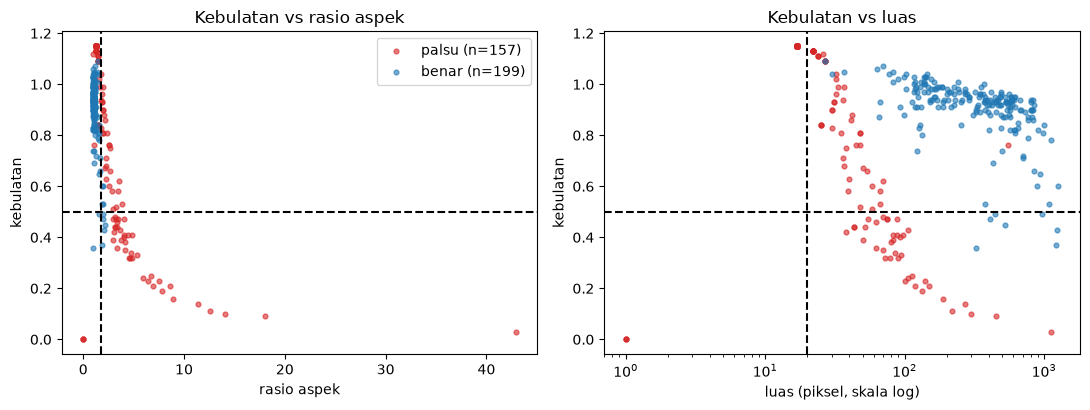

In [17]:
# komponen "benar" bila lebih dari separuh pikselnya berada di mask bercak acuan
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, mask_daun_awal(pra_)), cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))
    tk, lb = ukur_komponen(bersih)
    for _, r in tk.iterrows():
        benar = (mb[lb == r.label] > 0).mean() > 0.5
        baris.append([d.nama_file, d.kelas, benar, r.luas_px, r.kebulatan, r.rasio_aspek])
kom = pd.DataFrame(baris, columns=["citra", "kelas", "benar", "luas_px", "kebulatan", "rasio_aspek"])
kom.to_csv("../hasil/p6_komponen_benar_palsu.csv", index=False)
print("benar:", int(kom.benar.sum()), "| palsu:", int((~kom.benar).sum()))
print(kom.groupby("benar")[["luas_px", "kebulatan", "rasio_aspek"]].describe().T.round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for b, wr, lb_ in [(False, "tab:red", "palsu"), (True, "tab:blue", "benar")]:
    k = kom[kom.benar == b]
    ax[0].scatter(k.rasio_aspek, k.kebulatan, s=12, c=wr, alpha=0.6, label=f"{lb_} (n={len(k)})")
    ax[1].scatter(k.luas_px, k.kebulatan, s=12, c=wr, alpha=0.6, label=lb_)
ax[0].axvline(1.8, c="k", ls="--"); ax[0].axhline(0.5, c="k", ls="--")
ax[0].set_xlabel("rasio aspek"); ax[0].set_ylabel("kebulatan"); ax[0].set_title("Kebulatan vs rasio aspek"); ax[0].legend()
ax[1].axvline(20, c="k", ls="--"); ax[1].axhline(0.5, c="k", ls="--"); ax[1].set_xscale("log")
ax[1].set_xlabel("luas (piksel, skala log)"); ax[1].set_ylabel("kebulatan"); ax[1].set_title("Kebulatan vs luas")
plt.tight_layout(); plt.savefig("../hasil/p6_sebar_komponen.png", dpi=140); plt.show()

### Bukti tambahan untuk P4.3 dan P4.4

In [18]:
# P4.3: seberapa sering bercak ASLI memanjang atau menyatu (risiko aturan rasio aspek)
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    tk, _ = ukur_komponen(mb)
    baris.append([d.kelas, len(tk), int((tk.rasio_aspek > 1.8).sum()), tk.rasio_aspek.max(), tk.kebulatan.min()])
asli = pd.DataFrame(baris, columns=["kelas", "bercak_asli", "rasio>1.8", "rasio_maks", "kebulatan_min"])
print(asli.groupby("kelas").agg({"bercak_asli": "sum", "rasio>1.8": "sum", "rasio_maks": "max", "kebulatan_min": "min"}).round(2))
# komponen benar yang ditolak masing-masing syarat
b = kom[kom.benar]
print("benar tetapi luas < 20:", int((b.luas_px < 20).sum()), "| kebulatan < 0,5:", int((b.kebulatan < 0.5).sum()),
      "| rasio > 1,8:", int((b.rasio_aspek > 1.8).sum()), "dari", len(b))
p = kom[~kom.benar]
print("palsu yang lolos luas>=20:", int((p.luas_px >= 20).sum()), "| +kebulatan:", int(((p.luas_px >= 20) & (p.kebulatan >= 0.5)).sum()),
      "| +rasio:", int(((p.luas_px >= 20) & (p.kebulatan >= 0.5) & (p.rasio_aspek <= 1.8)).sum()), "dari", len(p))

        bercak_asli  rasio>1.8  rasio_maks  kebulatan_min
kelas                                                    
berat           179          3        2.06           0.52
ringan           40          1        2.00           0.81
benar tetapi luas < 20: 0 | kebulatan < 0,5: 7 | rasio > 1,8: 9 dari 199
palsu yang lolos luas>=20: 94 | +kebulatan: 56 | +rasio: 30 dari 157


In [19]:
# P4.4: luas total bercak hasil vs mask acuan pada teh_041, dan penyebabnya
img, md, mb = muat("teh_041.png")
pra_ = praproses(img, PARAM); m_daun = mask_daun_awal(pra_)
b0 = bercak_awal(pra_, m_daun)
b_open = cv2.morphologyEx(b0, cv2.MORPH_OPEN, SE(5))
b_oc = cv2.morphologyEx(b_open, cv2.MORPH_CLOSE, SE(5))
a = int((mb > 0).sum())
print("luas acuan:", a, "px")
for nm, m in [("bercak_awal (k=4)", b0), ("opening", b_open), ("opening+closing", b_oc)]:
    print(f"{nm:20s}: {int((m > 0).sum()):6d} px  ({100 * ((m > 0).sum() - a) / a:+.1f}% terhadap acuan)")
# variasi: tanpa praproses (median 3), dan ambang k lain, pada hasil akhir
mentah_b = bercak_awal(img, mask_daun_awal(img))
mentah_oc = cv2.morphologyEx(cv2.morphologyEx(mentah_b, cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))
print(f"tanpa praproses     : {int((mentah_oc > 0).sum()):6d} px  ({100 * ((mentah_oc > 0).sum() - a) / a:+.1f}%)")
for k in (3, 4, 6):
    mk = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun, k=k), cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))
    print(f"k={k}                 : {int((mk > 0).sum()):6d} px  ({100 * ((mk > 0).sum() - a) / a:+.1f}%)")
# nilai kanal R: pusat bercak, cincin tepi bercak (acuan dikurangi erosi), dan daun
R = pra_[:, :, 2].astype(float)
acu = mb > 0
pusat = cv2.erode(mb, SE(7)) > 0
cincin = acu & ~(cv2.erode(mb, SE(5)) > 0)
daun = (md > 0) & ~(cv2.dilate(mb, SE(9)) > 0)
med = np.median(R[daun]); mad = 1.4826 * np.median(np.abs(R[daun] - med))
print(f"R daun: median {med:.1f}, MAD {mad:.2f}, ambang k=4: {med + 4 * mad:.1f}")
print(f"R pusat bercak: {R[pusat].mean():.1f} | R cincin tepi bercak: {R[cincin].mean():.1f}")
print(f"piksel cincin acuan di atas ambang: {100 * (R[cincin] > med + 4 * mad).mean():.1f}%, pusat: {100 * (R[pusat] > med + 4 * mad).mean():.1f}%")
ker = cv2.dilate(b_oc, SE(3)) > 0
print("ringkas akurasi hasil: presisi", round(float(((b_oc > 0) & acu).sum() / (b_oc > 0).sum()), 3),
      "| recall", round(float(((b_oc > 0) & acu).sum() / acu.sum()), 3))

luas acuan: 4770 px
bercak_awal (k=4)   :   5682 px  (+19.1% terhadap acuan)
opening             :   4762 px  (-0.2% terhadap acuan)
opening+closing     :   4770 px  (+0.0% terhadap acuan)
tanpa praproses     :   3219 px  (-32.5%)
k=3                 :   5051 px  (+5.9%)
k=4                 :   4770 px  (+0.0%)
k=6                 :   4456 px  (-6.6%)
R daun: median 56.0, MAD 5.93, ambang k=4: 79.7
R pusat bercak: 190.9 | R cincin tepi bercak: 114.1
piksel cincin acuan di atas ambang: 97.3%, pusat: 100.0%
ringkas akurasi hasil: presisi 0.983 | recall 0.983


In [20]:
# P4.3 (lanjutan): kepekaan ambang rasio_maks dan luas_min pada 400 komponen hasil pembersihan
b = kom[kom.benar]; p = kom[~kom.benar]
print("rasio_maks | benar ditolak | palsu lolos   (luas_min 20, bulat_min 0,5)")
for r in [1.5, 1.8, 2.2, 2.7, 99]:
    ok = lambda t: (t.luas_px >= 20) & (t.kebulatan >= 0.5) & (t.rasio_aspek <= r)
    print(f"{r:>10} | {int((~ok(b)).sum()):13d} | {int(ok(p).sum()):12d}")
print("luas_min   | benar ditolak | palsu lolos   (bulat_min 0,5, rasio_maks 1,8)")
for lm in [20, 30, 50, 80]:
    ok = lambda t: (t.luas_px >= lm) & (t.kebulatan >= 0.5) & (t.rasio_aspek <= 1.8)
    print(f"{lm:>10} | {int((~ok(b)).sum()):13d} | {int(ok(p).sum()):12d}")
q = p[(p.luas_px >= 20) & (p.kebulatan >= 0.5) & (p.rasio_aspek <= 1.8)]
print("palsu yang lolos semua aturan: luas median", q.luas_px.median(), "maks", q.luas_px.max(), "| per kelas", q.groupby("kelas").size().to_dict())

rasio_maks | benar ditolak | palsu lolos   (luas_min 20, bulat_min 0,5)
       1.5 |            17 |           25
       1.8 |            11 |           30
       2.2 |             7 |           41
       2.7 |             7 |           50
        99 |             7 |           56
luas_min   | benar ditolak | palsu lolos   (bulat_min 0,5, rasio_maks 1,8)
        20 |            11 |           30
        30 |            12 |            6
        50 |            14 |            1
        80 |            19 |            1
palsu yang lolos semua aturan: luas median 24.0 maks 550.0 | per kelas {'berat': 6, 'ringan': 7, 'sehat': 17}


In [21]:
# P4.4 (lanjutan): pisahkan pengaruh penapis median, opening, dan closing pada luas bercak teh_041
img, md, mb = muat("teh_041.png"); a = mb > 0
def tahap(p, nama):
    R = p[:, :, 2].astype(float); d = (md > 0) & ~(cv2.dilate(mb, SE(9)) > 0)
    med = np.median(R[d]); mad = 1.4826 * np.median(np.abs(R[d] - med))
    b0 = bercak_awal(p, mask_daun_awal(p)); o = cv2.morphologyEx(b0, cv2.MORPH_OPEN, SE(5)); c = cv2.morphologyEx(o, cv2.MORPH_CLOSE, SE(5))
    print(f"{nama} | MAD {mad:.1f}, ambang {med + 4 * mad:.1f}")
    for k, x in [("awal", b0), ("opening", o), ("opening+closing", c)]:
        x = x > 0
        print(f"   {k:16s}: {int(x.sum()):5d} px | presisi {(x & a).sum() / x.sum():.3f} | recall {(x & a).sum() / a.sum():.3f}")
tahap(praproses(img, PARAM), "dengan median 3 (praproses sendiri)")
tahap(praproses(img, {**PARAM, "penapis": "none"}), "tanpa penapis median")

dengan median 3 (praproses sendiri) | MAD 5.9, ambang 79.7
   awal            :  5682 px | presisi 0.830 | recall 0.988
   opening         :  4762 px | presisi 0.983 | recall 0.982
   opening+closing :  4770 px | presisi 0.983 | recall 0.983
tanpa penapis median | MAD 13.3, ambang 109.4
   awal            :  4015 px | presisi 0.940 | recall 0.791
   opening         :  3114 px | presisi 1.000 | recall 0.653
   opening+closing :  3219 px | presisi 1.000 | recall 0.675


# Bagian 5. Integrasi: modul analisis bercak (`src/bercak.py`)

## Langkah 5.1 Modul bercak.py
Tujuh TODO dilengkapi di `src/bercak.py` (opening dan closing, label komponen, ukuran, penyaringan, persen bercak, kelas). Uji singkat pada tiga citra:

In [22]:
import importlib, bercak
importlib.reload(bercak)
for nama in ["teh_041.png", "teh_021.png", "teh_011.png"]:
    img, md, mb = muat(nama)
    h = bercak.analisis_daun(praproses(img, PARAM))
    print(nama, "| jumlah", h["jumlah_bercak"], "| persen", h["persen_bercak"], "| kelas", h["kelas"])

teh_041.png | jumlah 10 | persen 6.835 | kelas Bercak Berat
teh_021.png | jumlah 5 | persen 0.375 | kelas Bercak Ringan
teh_011.png | jumlah 1 | persen 0.036 | kelas Sehat


## Langkah 5.2 Penentuan parameter (kalibrasi pada separuh data, uji pada separuh lainnya)

In [23]:
# kalibrasi = citra bernomor ganjil (30), uji = citra bernomor genap (30); keduanya memuat 10 sehat, 10 ringan, 10 berat
from itertools import product
PRA = {n: praproses(muat(n)[0], PARAM) for n in label.nama_file}
ACU = dict(zip(label.nama_file, label.persen_bercak))
KEL = dict(zip(label.nama_file, label.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"})))
kal, uji_ = list(label.nama_file[0::2]), list(label.nama_file[1::2])
MD = {n: bercak.mask_daun_awal(PRA[n]) for n in PRA}
BIN = {(n, k): bercak.bercak_awal(PRA[n], MD[n], kanal=2, k=k) for n in PRA for k in (3.0, 4.0, 5.0)}

def persen_cfg(p):
    p = {**bercak.PARAM_BERCAK, **p}
    out = {}
    for n in PRA:
        m_b, _ = bercak.ukur_dan_saring(bercak.bersihkan(BIN[(n, p["k"])], p), p)
        out[n] = 100.0 * (m_b > 0).sum() / (MD[n] > 0).sum()
    return out

def kelas_dari(pers, br, bb):
    return "Bercak Berat" if pers >= bb else ("Bercak Ringan" if pers >= br else "Sehat")

hasil_grid = []
for bentuk_, op_, cl_, lm_, k_ in product(["elips", "persegi"], [3, 5, 7], [0, 5], [20, 30, 50], [3.0, 4.0, 5.0]):
    pers = persen_cfg({"se_bentuk": bentuk_, "se_open": op_, "se_close": cl_, "luas_min": lm_, "k": k_})
    for br, bb in product([0.05, 0.10, 0.15], [1.5, 2.0, 2.5]):
        for nm, himp in [("kal", kal), ("uji", uji_)]:
            akur = np.mean([kelas_dari(pers[n], br, bb) == KEL[n] for n in himp])
            gal = np.mean([abs(pers[n] - ACU[n]) for n in himp])
            hasil_grid.append([bentuk_, op_, cl_, lm_, k_, br, bb, nm, akur, gal])
G = pd.DataFrame(hasil_grid, columns=["bentuk", "open", "close", "luas_min", "k", "b_ringan", "b_berat", "himp", "akurasi", "galat"])
Gw = G.pivot_table(index=["bentuk", "open", "close", "luas_min", "k", "b_ringan", "b_berat"], columns="himp", values=["akurasi", "galat"])
Gw.columns = [f"{a}_{b}" for a, b in Gw.columns]
Gw = Gw.reset_index().sort_values(["akurasi_kal", "galat_kal"], ascending=[False, True])
print("10 konfigurasi terbaik pada data kalibrasi:")
print(Gw.head(10).round(3).to_string(index=False))
Gw.to_csv("../hasil/p6_grid_parameter.csv", index=False)

10 konfigurasi terbaik pada data kalibrasi:
bentuk  open  close  luas_min   k  b_ringan  b_berat  akurasi_kal  akurasi_uji  galat_kal  galat_uji
 elips     3      5        50 3.0      0.05      1.5        0.967        0.967      0.473      0.457
 elips     3      5        50 3.0      0.05      2.0        0.967        0.933      0.473      0.457
 elips     3      5        50 3.0      0.05      2.5        0.967        0.933      0.473      0.457
 elips     3      5        50 3.0      0.10      1.5        0.967        0.967      0.473      0.457
 elips     3      5        50 3.0      0.10      2.0        0.967        0.933      0.473      0.457
 elips     3      5        50 3.0      0.10      2.5        0.967        0.933      0.473      0.457
 elips     3      5        50 3.0      0.15      1.5        0.967        0.967      0.473      0.457
 elips     3      5        50 3.0      0.15      2.0        0.967        0.933      0.473      0.457
 elips     3      5        50 3.0      0.15    

In [24]:
# pembanding: parameter bawaan, dan parameter dari temuan Bagian 3-4 (persegi 7, luas_min 30), pada kedua himpunan
def akurasi_cfg(p, br=0.10, bb=2.0):
    pers = persen_cfg(p)
    return {nm: round(float(np.mean([kelas_dari(pers[n], br, bb) == KEL[n] for n in himp])), 3) for nm, himp in [("kal", kal), ("uji", uji_), ("semua", list(PRA))]}
print("bawaan                  :", akurasi_cfg({}))
print("temuan Bagian 3-4       :", akurasi_cfg({"se_bentuk": "persegi", "se_open": 7, "se_close": 7, "luas_min": 30}))
print("SE elips 5, luas_min 30 :", akurasi_cfg({"luas_min": 30}))

bawaan                  : {'kal': 0.967, 'uji': 0.933, 'semua': 0.95}
temuan Bagian 3-4       : {'kal': 0.933, 'uji': 0.967, 'semua': 0.95}
SE elips 5, luas_min 30 : {'kal': 0.967, 'uji': 1.0, 'semua': 0.983}


## Langkah 5.2 (lanjutan) Parameter akhir dan evaluasi menyeluruh (Kode 5.2, Tabel 12)

{
  "kanal": 2,
  "k": 5.0,
  "se_bentuk": "elips",
  "se_open": 3,
  "se_close": 5,
  "luas_min": 50,
  "bulat_min": 0.5,
  "rasio_maks": 1.8,
  "batas_ringan": 0.1,
  "batas_berat": 1.5,
  "mm_per_px": 0.4375
}
Galat absolut rerata persen bercak: 0.489
Korelasi persen prediksi vs acuan  : 0.884
Akurasi kelas                      : 0.983
prediksi       Bercak Berat  Bercak Ringan  Sehat
acuan                                            
Bercak Berat             19              0      1
Bercak Ringan             0             20      0
Sehat                     0              0     20
kondisi
bayangan          1.00
gelap             1.00
kontras_rendah    0.92
normal            1.00
terang            1.00
Name: benar, dtype: float64
kalibrasi : akurasi 0.967 | galat persen 0.528
uji       : akurasi 1.000 | galat persen 0.451


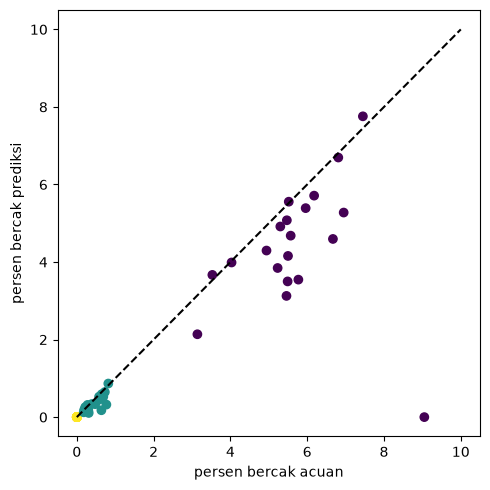

In [25]:
# parameter akhir = konfigurasi terbaik pada data kalibrasi (selisih dengan konfigurasi lain hanya 1-2 citra);
# batas_ringan tetap 0,10 karena 0,05 dan 0,10 sama baiknya
PB = {"se_bentuk": "elips", "se_open": 3, "se_close": 5, "luas_min": 50, "k": 5.0,
      "batas_ringan": 0.10, "batas_berat": 1.5}
bercak.simpan_param(PB)
print(open("../hasil/param_bercak.json").read())

baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    h = bercak.analisis_daun(PRA[d.nama_file], PB)
    baris.append([d.nama_file, d.kelas, d.kondisi_cahaya, d.persen_bercak, h["persen_bercak"],
                  jumlah_komponen(mb), h["jumlah_bercak"], h["kelas"]])
ev = pd.DataFrame(baris, columns=["nama", "kelas", "kondisi", "persen_acuan", "persen_prediksi",
                                  "jumlah_acuan", "jumlah_prediksi", "kelas_prediksi"])
ev["kelas_acuan"] = ev.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"})
ev.to_csv("../hasil/p6_evaluasi_bercak.csv", index=False)

print("Galat absolut rerata persen bercak:", (ev.persen_prediksi - ev.persen_acuan).abs().mean().round(3))
print("Korelasi persen prediksi vs acuan  :", ev[["persen_prediksi", "persen_acuan"]].corr().iloc[0, 1].round(3))
print("Akurasi kelas                      :", (ev.kelas_prediksi == ev.kelas_acuan).mean().round(3))
print(pd.crosstab(ev.kelas_acuan, ev.kelas_prediksi, rownames=["acuan"], colnames=["prediksi"]))
print(ev.assign(benar=ev.kelas_prediksi == ev.kelas_acuan).groupby("kondisi").benar.mean().round(2))
for nm, himp in [("kalibrasi", kal), ("uji", uji_)]:
    e = ev[ev.nama.isin(himp)]
    print(f"{nm:10s}: akurasi {(e.kelas_prediksi == e.kelas_acuan).mean():.3f} | galat persen {(e.persen_prediksi - e.persen_acuan).abs().mean():.3f}")

plt.figure(figsize=(5, 5))
plt.scatter(ev.persen_acuan, ev.persen_prediksi, c=ev.kelas.astype("category").cat.codes)
plt.plot([0, 10], [0, 10], "k--"); plt.xlabel("persen bercak acuan"); plt.ylabel("persen bercak prediksi")
plt.tight_layout(); plt.savefig("../hasil/p6_persen_prediksi_vs_acuan.png", dpi=140); plt.show()

## Langkah 5.3 Analisis kesalahan

  citra        kondisi        acuan prediksi  % acuan  % prediksi  bercak acuan px  % acuan di mask awal  terdeteksi awal px  sesudah bersih px  sesudah saring px  palsu px
teh_049 kontras_rendah Bercak Berat    Sehat     9.05         0.0             5609                  89.8                   0                  0                  0         0


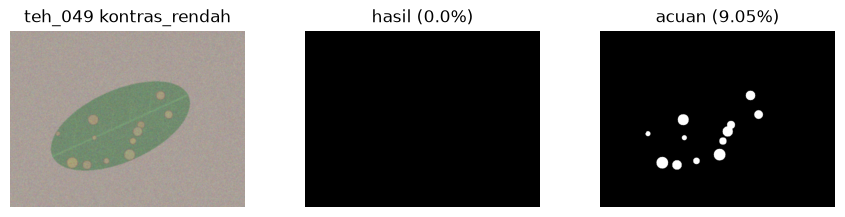

In [26]:
salah = ev[ev.kelas_prediksi != ev.kelas_acuan]
SEf = lambda k: cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
baris, panel, judul = [], [], []
for _, r in salah.iterrows():
    img, md, mb = muat(r.nama); pra_ = PRA[r.nama]; a = mb > 0
    h = bercak.analisis_daun(pra_, PB)
    m = MD[r.nama] > 0
    b0 = bercak.bercak_awal(pra_, MD[r.nama], kanal=2, k=PB["k"]) > 0
    bs = bercak.bersihkan((b0 * 255).astype(np.uint8), {**bercak.PARAM_BERCAK, **PB}) > 0
    hs = h["mask_bercak"] > 0
    baris.append([r.nama[:7], r.kondisi, r.kelas_acuan, r.kelas_prediksi, r.persen_acuan, r.persen_prediksi,
                  int(a.sum()), round(100 * (m & a).sum() / max(a.sum(), 1), 1), int((b0 & a).sum()),
                  int((bs & a).sum()), int((hs & a).sum()), int((hs & ~a).sum())])
    panel += [pra_, h["mask_bercak"], mb]; judul += [f"{r.nama[:7]} {r.kondisi}", f"hasil ({r.persen_prediksi}%)", f"acuan ({r.persen_acuan}%)"]
cols = ["citra", "kondisi", "acuan", "prediksi", "% acuan", "% prediksi", "bercak acuan px",
        "% acuan di mask awal", "terdeteksi awal px", "sesudah bersih px", "sesudah saring px", "palsu px"]
tab_salah = pd.DataFrame(baris, columns=cols)
print(tab_salah.to_string(index=False))
tab_salah.to_csv("../hasil/p6_analisis_kesalahan.csv", index=False)
tampil(panel, judul, baris=len(salah), ukuran=(9, 2.2 * len(salah)))
plt.savefig("../hasil/p6_panel_kesalahan.png", dpi=110, bbox_inches="tight"); plt.show()

### Bukti tambahan untuk P5.1 sampai P5.5

In [27]:
# P5.1: persen prediksi pada citra yang kelasnya benar (apakah benar-benar akurat, bukan kebetulan)
ev["galat_persen"] = (ev.persen_prediksi - ev.persen_acuan)
print(ev.groupby("kelas")[["persen_acuan", "persen_prediksi", "galat_persen"]].agg(["mean", "min", "max"]).round(2))
print("persen prediksi lebih rendah dari acuan pada", int((ev.galat_persen < 0).sum()), "dari", len(ev), "citra; rerata galat berat:",
      ev[ev.kelas == "berat"].galat_persen.mean().round(2))
# P5.2: rentang persen acuan per kelas pada label.csv dan rentang prediksi
print(label.groupby("kelas").persen_bercak.agg(["min", "max"]))
print(ev.groupby("kelas").persen_prediksi.agg(["min", "max"]).round(3))
# P5.4: kepekaan batas ringan dan berat terhadap dua jenis kesalahan
print("batas_ringan | berbercak->sehat | sehat->berbercak")
for br in [0.02, 0.05, 0.10, 0.15, 0.20, 0.30]:
    kp = ev.persen_prediksi.map(lambda x: kelas_dari(x, br, PB["batas_berat"]))
    fn = int(((ev.kelas != "sehat") & (kp == "Sehat")).sum()); fp = int(((ev.kelas == "sehat") & (kp != "Sehat")).sum())
    print(f"{br:>12} | {fn:16d} | {fp:16d}")
print("batas_berat  | berat->ringan | ringan->berat")
for bb in [1.0, 1.5, 2.0, 2.5, 3.0]:
    kp = ev.persen_prediksi.map(lambda x: kelas_dari(x, PB["batas_ringan"], bb))
    print(f"{bb:>12} | {int(((ev.kelas == 'berat') & (kp != 'Bercak Berat')).sum()):13d} | {int(((ev.kelas == 'ringan') & (kp == 'Bercak Berat')).sum()):13d}")

       persen_acuan             persen_prediksi             galat_persen            
               mean   min   max            mean   min   max         mean   min   max
kelas                                                                               
berat          5.70  3.14  9.05            4.40  0.00  7.76        -1.31 -9.05  0.31
ringan         0.44  0.18  0.82            0.34  0.11  0.87        -0.10 -0.46  0.05
sehat          0.00  0.00  0.00            0.00  0.00  0.00         0.00  0.00  0.00
persen prediksi lebih rendah dari acuan pada 33 dari 60 citra; rerata galat berat: -1.31
         min   max
kelas             
berat   3.14  9.05
ringan  0.18  0.82
sehat   0.00  0.00
          min    max
kelas               
berat   0.000  7.758
ringan  0.107  0.866
sehat   0.000  0.000
batas_ringan | berbercak->sehat | sehat->berbercak
        0.02 |                1 |                0
        0.05 |                1 |                0
         0.1 |                1 |               

In [28]:
# P5.5: uji bentuk tak beraturan. Pada 12 citra daun sehat (kondisi normal, terang, gelap) digambar 3 bercak buatan
# berwarna sama dengan bercak teh_041, luas hampir sama (sekitar 280 px) tetapi bentuk lonjong dengan rasio sumbu 1, 1,5, 2, 3
# dan bentuk bintang (tepi bergerigi); dihitung berapa yang bertahan dari pembersihan dan dari penyaringan.
rng = np.random.default_rng(1014)
img41, md41, mb41 = muat("teh_041.png")
warna_bercak = tuple(int(v) for v in img41[cv2.erode(mb41, SEf(9)) > 0].mean(axis=0))
sehat_uji = [n for n in label[(label.kelas == "sehat") & (label.kondisi_cahaya.isin(["normal", "terang", "gelap"]))].nama_file]
pp = {**bercak.PARAM_BERCAK, **PB}

def gambar(img, md, jenis, pusat, sudut):
    A = 280.0
    if jenis == "bintang":
        R, r = 14.0, 6.0
        t = np.linspace(0, 2 * np.pi, 11)[:-1]
        rad = np.where(np.arange(10) % 2 == 0, R, r)
        poly = np.stack([pusat[0] + rad * np.cos(t + sudut), pusat[1] + rad * np.sin(t + sudut)], 1).astype(np.int32)
        cv2.fillPoly(img, [poly], warna_bercak); return
    rasio = float(jenis); b = np.sqrt(A / (np.pi * rasio)); a_ = b * rasio
    cv2.ellipse(img, (int(pusat[0]), int(pusat[1])), (int(round(a_)), int(round(b))), np.degrees(sudut), 0, 360, warna_bercak, -1)

hasil = []
for jenis in ["1", "1.5", "2", "3", "bintang"]:
    ada = bertahan_bersih = bertahan_saring = 0
    for n in sehat_uji:
        img, md, _ = muat(n)
        ys, xs = np.where(cv2.erode(md, SEf(61)) > 0)
        titik = [(xs[i], ys[i]) for i in rng.choice(len(xs), 3, replace=False)]
        for t in titik: gambar(img, md, jenis, t, rng.uniform(0, np.pi))
        pr_ = praproses(img, PARAM); m_ = bercak.mask_daun_awal(pr_)
        bers = bercak.bersihkan(bercak.bercak_awal(pr_, m_, kanal=2, k=pp["k"]), pp)
        _, daftar = bercak.ukur_dan_saring(bers, pp)
        n_, l_, st_, cen_ = cv2.connectedComponentsWithStats((bers > 0).astype(np.uint8), connectivity=8)
        for t in titik:
            ada += 1
            bertahan_bersih += any(np.hypot(*(cen_[i] - np.array(t))) < 8 for i in range(1, n_))
            bertahan_saring += any(np.hypot(d["cx"] - t[0], d["cy"] - t[1]) < 8 for d in daftar)
    hasil.append([jenis, ada, bertahan_bersih, bertahan_saring])
print(pd.DataFrame(hasil, columns=["bentuk (rasio sumbu)", "bercak buatan", "bertahan setelah pembersihan", "lolos penyaringan"]))

  bentuk (rasio sumbu)  bercak buatan  bertahan setelah pembersihan  lolos penyaringan
0                    1             36                            31                 28
1                  1.5             36                            28                 25
2                    2             36                            30                  9
3                    3             36                            32                  0
4              bintang             36                            30                  0


In [29]:
# P5.4: parameter deteksi (k, luas_min) vs dua jenis kesalahan, pada 60 citra (batas 0,10 / 1,5)
baris = []
for k_, lm_ in product([3.0, 4.0, 5.0], [20, 30, 50]):
    pers = persen_cfg({"se_bentuk": "elips", "se_open": 3, "se_close": 5, "luas_min": lm_, "k": k_})
    kp = {n: kelas_dari(pers[n], 0.10, 1.5) for n in pers}
    fn = sum(1 for n in pers if KEL[n] != "Sehat" and kp[n] == "Sehat")
    fp = sum(1 for n in pers if KEL[n] == "Sehat" and kp[n] != "Sehat")
    baris.append([k_, lm_, fn, fp, round(float(np.mean([kp[n] == KEL[n] for n in pers])), 3)])
print(pd.DataFrame(baris, columns=["k", "luas_min", "berbercak->sehat", "sehat->berbercak", "akurasi"]).to_string(index=False))
# pemeriksaan kewajaran mask daun (usulan penanda 'perlu diperiksa')
fr = pd.Series({n: (MD[n] > 0).mean() for n in PRA})
print("proporsi luas mask daun terhadap citra: median", round(fr.median(), 3), "min", round(fr.min(), 3), "maks", round(fr.max(), 3),
      "| citra dengan nilai > 0,35:", list(fr[fr > 0.35].index))

  k  luas_min  berbercak->sehat  sehat->berbercak  akurasi
3.0        20                 2                 0    0.967
3.0        30                 2                 0    0.967
3.0        50                 2                 0    0.967
4.0        20                 1                 0    0.983
4.0        30                 1                 0    0.983
4.0        50                 1                 0    0.983
5.0        20                 1                 0    0.983
5.0        30                 1                 0    0.983
5.0        50                 1                 0    0.983
proporsi luas mask daun terhadap citra: median 0.245 min 0.189 maks 0.301 | citra dengan nilai > 0,35: []
